In [13]:
import time
import csv
import struct
import json
from tqdm import tqdm

exp_name = 'Nov5'

TRAIN_JSONL = '../data/' + exp_name + '/1_Quasi_Static_Log_train.jsonl'
TEST_JSONL = '../data/' + exp_name + '/1_Quasi_Static_Log_test.jsonl'

In [14]:
import json
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error

# === Load training data ===
train_data = []
with open(TRAIN_JSONL, 'r') as f:
    for line in f:
        train_data.append(json.loads(line))
print(f"Loaded {len(train_data)} training records.")

# === Load test data ===
test_data = []
with open(TEST_JSONL, 'r') as f:
    for line in f:
        test_data.append(json.loads(line))
print(f"Loaded {len(test_data)} test records.")

# === Extract features: Orientation angles ===
X_train = np.array([[entry["robot_data"]['X_Pos'][3], entry["robot_data"]['X_Pos'][4], entry["robot_data"]['X_Pos'][5]] for entry in train_data])  # rx, ry, rz
X_test = np.array([[entry["robot_data"]['X_Pos'][3], entry["robot_data"]['X_Pos'][4], entry["robot_data"]['X_Pos'][5]] for entry in test_data])  # rx, ry, rz

# === Target: full FF_EE vector (force + torque) ===
y_train = np.array([entry['robot_data']['FF_EE'][:6] for entry in train_data])  # FF_EE[0:6]
y_test = np.array([entry['robot_data']['FF_EE'][:6] for entry in test_data])  # FF_EE[0:6]

# === Create pipeline ===
degree = 3
model = Pipeline([
    ('poly', PolynomialFeatures(degree)),
    ('regressor', MultiOutputRegressor(LinearRegression()))
])
model.fit(X_train, y_train)

# === Evaluate ===
y_pred = model.predict(X_test)
total_mse = mean_squared_error(y_test, y_pred)
print(f"Total MSE (FF_EE[0:6]): {total_mse:.6f}")

for i in range(6):
    mse_i = mean_squared_error(y_test[:, i], y_pred[:, i])
    print(f"FF_EE[{i}] MSE: {mse_i:.6f}")


Loaded 441 training records.
Loaded 50 test records.
Total MSE (FF_EE[0:6]): 0.000640
FF_EE[0] MSE: 0.000804
FF_EE[1] MSE: 0.000120
FF_EE[2] MSE: 0.002904
FF_EE[3] MSE: 0.000005
FF_EE[4] MSE: 0.000007
FF_EE[5] MSE: 0.000000


In [15]:
import os
import pandas as pd

# === Save actual and predicted values to CSV ===
os.makedirs('../data/' + exp_name, exist_ok=True)

# Create DataFrame with actual and predicted values
results_df = pd.DataFrame({
    'Sample_Index': range(len(y_test)),
    'Actual_Force_Fx': y_test[:, 0],
    'Predicted_Force_Fx': y_pred[:, 0],
    'Actual_Force_Fy': y_test[:, 1],
    'Predicted_Force_Fy': y_pred[:, 1],
    'Actual_Force_Fz': y_test[:, 2],
    'Predicted_Force_Fz': y_pred[:, 2],
    'Actual_Torque_Mx': y_test[:, 3],
    'Predicted_Torque_Mx': y_pred[:, 3],
    'Actual_Torque_My': y_test[:, 4],
    'Predicted_Torque_My': y_pred[:, 4],
    'Actual_Torque_Mz': y_test[:, 5],
    'Predicted_Torque_Mz': y_pred[:, 5]
})

# Save to CSV
csv_path = '../data/' + exp_name + '/test_predictions.csv'
results_df.to_csv(csv_path, index=False)
print(f"✅ Test predictions saved to {csv_path}")
print(f"📊 Total samples: {len(results_df)}")


✅ Test predictions saved to ../data/Nov5/test_predictions.csv
📊 Total samples: 50


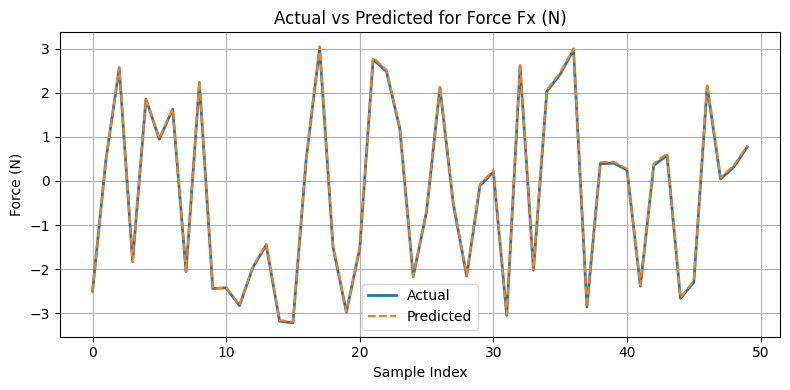

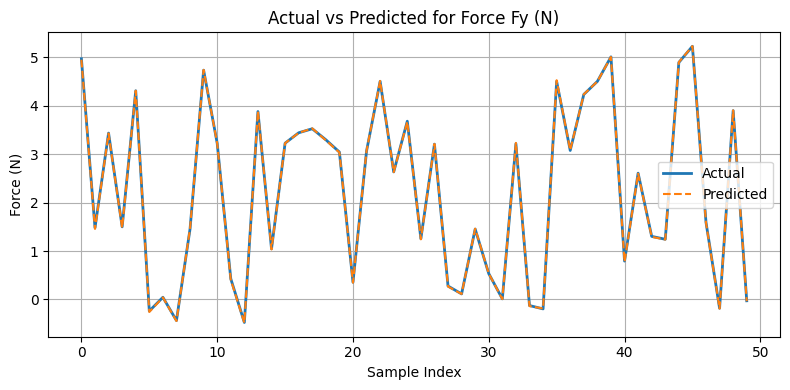

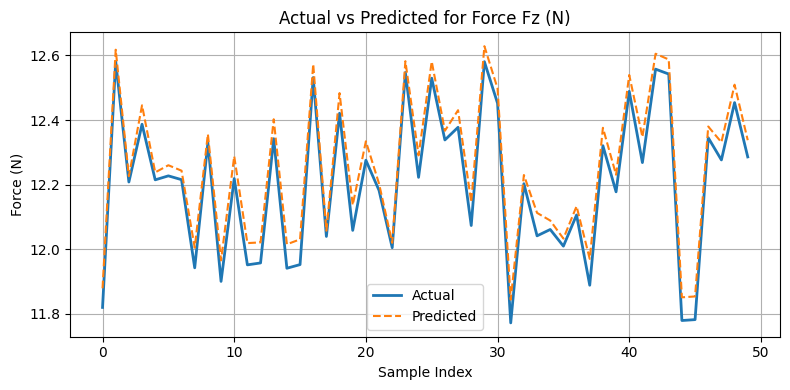

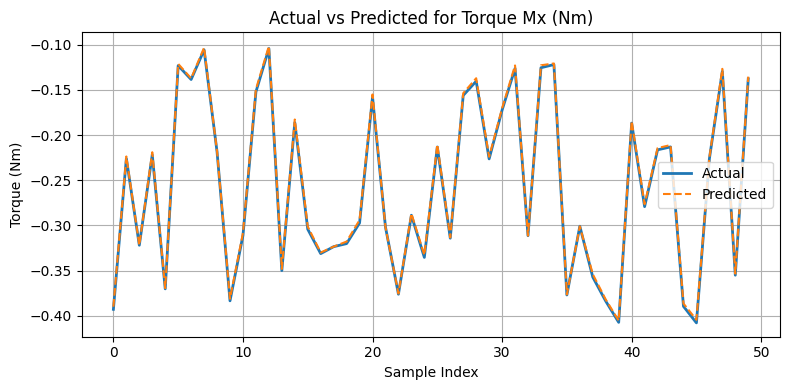

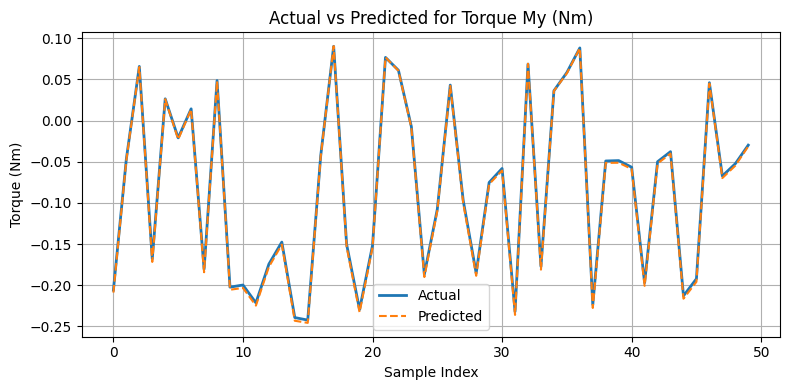

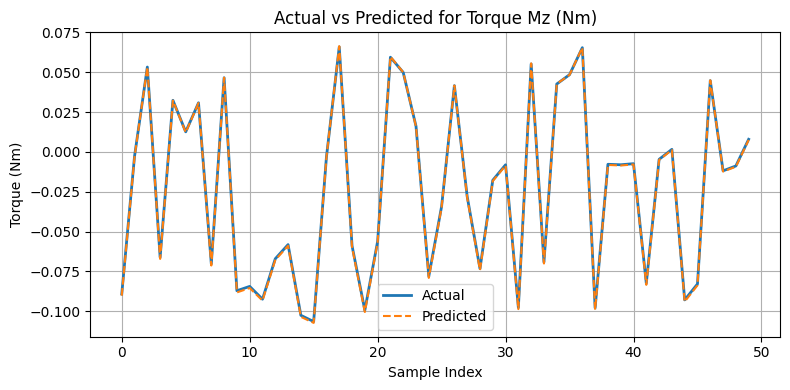

In [16]:
import matplotlib.pyplot as plt

# Number of points to plot
N = 100
subset_indices = np.arange(min(N, len(X_test)))

# Updated labels for all 6 components
component_labels = [
    'Force Fx (N)',
    'Force Fy (N)',
    'Force Fz (N)',
    'Torque Mx (Nm)',
    'Torque My (Nm)',
    'Torque Mz (Nm)'
]

# Y-axis labels with units
y_labels = ['Force (N)', 'Force (N)', 'Force (N)', 'Torque (Nm)', 'Torque (Nm)', 'Torque (Nm)']

# Plot all components
for i in range(6):
    plt.figure(figsize=(8, 4))
    plt.plot(subset_indices, y_test[subset_indices, i], label='Actual', linewidth=2)
    plt.plot(subset_indices, y_pred[subset_indices, i], label='Predicted', linestyle='--')
    plt.title(f'Actual vs Predicted for {component_labels[i]}')
    plt.xlabel('Sample Index')
    plt.ylabel(y_labels[i])
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [17]:
import os
import joblib
# === Save model ===
os.makedirs('../models/' + exp_name, exist_ok=True)
joblib.dump(model, '../models/' + exp_name + '/1_Quasi_Static_Poly.pkl')
print("Model saved to ../models/" + exp_name + "/1_Quasi_Static_Poly.pkl")

Model saved to ../models/Nov5/1_Quasi_Static_Poly.pkl
